# Market, level 3: whole days

The reference scenario played over the 14 test days (1-14 July 2016), every step
checked against rules that must always hold, then an overview of how the market
behaves over those days.

[Level 1](market_1_formulas.ipynb) checks each formula on numbers worked out by
hand, [level 2](market_2_step.ipynb) one step phase by phase. This level catches
what only shows over many steps: a rare case, or state carried wrongly from one
step to the next (a battery, a reputation, the hour's tariffs).

Participants bid with the market's own rule, as in level 2. The checks are
grouped:

| Group | What it guards |
|---|---|
| clearing | who trades with whom, at which price, how much |
| energy | the trades and the battery add up for every participant |
| money | every payment leaves one party and reaches another |
| grid and fees | the power flow, the trades' paths and losses, the fees |
| network | the power flow's energy balance, checked from outside (background off) |
| reputation | eq. 12's blend, step after step |
| bidding rule | a property of the rule, not of the market |

In [1]:
import sys
from copy import deepcopy
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core" / "market").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from core.config import store
from core.config.scenario import Scenario, load_prices, price_at
from core.grid.powerflow import SimBenchGrid
from core.market.dso import DSO_ID
from core.market.lem import LocalEnergyMarket, StepRecord

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

SCENARIO_FILE = ROOT / "config" / "scenarios" / "validate_market.json"
DAYS = [f"2016-07-{d:02d}" for d in range(1, 15)]

scenario = store.load(SCENARIO_FILE)   # read only
print(f"{scenario.name}: {len(scenario.participants)} participants on {scenario.grid.code}, "
      f"{len(DAYS)} days from {DAYS[0]}")

validate_market: 5 participants on 1-LV-rural1--0-sw, 14 days from 2016-07-01


## Play the days

`run_day` plays one day with the scenario as it is; `run_days` plays several and
keeps every step's record with its day.

In [2]:
def run_day(s: Scenario, day: str) -> tuple[LocalEnergyMarket, list[StepRecord]]:
    # Play one day of a copy of the scenario; return the market and every step's record.
    s = deepcopy(s)
    s.grid.day = day
    lem = LocalEnergyMarket(s)
    lem.reset()
    records = lem.run_to_end()
    return lem, records


def run_days(s: Scenario, days: list[str]) -> list[tuple[str, LocalEnergyMarket, list[StepRecord]]]:
    # Play several days; each entry is (day, market, records).
    played = []
    for day in days:
        lem, records = run_day(s, day)
        played.append((day, lem, records))
    return played


played = run_days(scenario, DAYS)

n_steps = 0
for day, lem, records in played:
    n_steps += len(records)
print(f"played {n_steps} steps")

played 336 steps

## The rules every step keeps

`check_days` goes through every step of every day. A rule that holds says
PASS; one that breaks says FAIL with its first three failures (day, step, what).
`checked` is how often the rule was tested.

Two rules from the earlier notebook are left out because they hold by
definition: *satisfied + deferred = demand* and the balance $B$ itself are
computed that way in `ParticipantOutcome`, so they cannot fail. The battery is
checked instead from outside: its energy recomputed step by step from its charges
and discharges.

In [3]:
TOL = 1e-6
GROUPS = {
    "clearing": ["every order cleared", "no self-trade", "DSO only in stage 3",
                 "DSO trades at the hour's tariffs", "peer price between ask and bid",
                 "traded = order quantity", "no trade without an order"],
    "energy": ["bought and sold = the trades", "battery recomputed from charge and discharge",
               "battery inside its window", "never charge and discharge at once"],
    "money": ["money adds up (participants + DSO = 0)", "DSO balance = sold - bought (eq. 7)",
              "DSO balance = -B_grid", "fee = sum of its parts", "fee paid once"],
    "grid and fees": ["power flow converges", "loss = d q kappa (eq. 18)",
                      "DSO trade runs to the transformer, no zone bonus"],
    "reputation": ["reputation in 0-1", "reputation = decay blend of the step's score"],
    "bidding rule": ["nothing left untraded"],
}


class Rules:
    """Counts how often each rule was checked and keeps where it failed."""

    def __init__(self):
        self.checked = {}
        self.failures = {}
        for names in GROUPS.values():
            for name in names:
                self.checked[name] = 0
                self.failures[name] = []

    def rule(self, name, ok, where, text=""):
        self.checked[name] += 1
        if not ok:
            self.failures[name].append(f"{where}: {text}" if text else where)

    def table(self):
        rows = []
        for group, names in GROUPS.items():
            for name in names:
                rows.append({"group": group, "check": name, "checked": self.checked[name],
                             "result": "FAIL" if self.failures[name] else "PASS",
                             "first failures": "; ".join(self.failures[name][:3])})
        return pd.DataFrame(rows).set_index(["group", "check"])


def traded_by(trades, pid, as_buyer):
    # The kWh participant pid bought (as_buyer) or sold in these trades
    total = 0.0
    for t in trades:
        if as_buyer and t.buyer_id == pid:
            total += t.quantity
        if not as_buyer and t.seller_id == pid:
            total += t.quantity
    return total


def check_trades(rules, r, at, fit, utility, upstream, d):
    orders = {o.agent_id: o for o in r.orders}
    for t in r.trades:
        where = f"{at} {t.seller_id}->{t.buyer_id}"
        rules.rule("no self-trade", t.buyer_id != t.seller_id, where)

        with_dso = t.buyer_id == DSO_ID or t.seller_id == DSO_ID
        rules.rule("DSO only in stage 3", with_dso == (t.stage == 3), where, f"stage {t.stage}")

        if with_dso:
            if t.buyer_id == DSO_ID:     # the DSO buys at the feed-in tariff
                tariff, pid = fit, t.seller_id
            else:                        # and sells at the utility price
                tariff, pid = utility, t.buyer_id
            rules.rule("DSO trades at the hour's tariffs", abs(t.price - tariff) < TOL,
                       where, f"{t.price} not {tariff}")
            to_transformer = abs(t.distance - upstream[pid]) < TOL
            rules.rule("DSO trade runs to the transformer, no zone bonus",
                       to_transformer and t.fee_parts.zone == 0, where)
        else:
            ask = orders[t.seller_id].price
            bid = orders[t.buyer_id].price
            rules.rule("peer price between ask and bid", ask - TOL <= t.price <= bid + TOL, where)

        loss = t.distance * t.quantity * d.loss_factor
        rules.rule("loss = d q kappa (eq. 18)", abs(t.transmission_loss - loss) < TOL, where)
        rules.rule("fee = sum of its parts", abs(t.fees - t.fee_parts.total) < TOL, where)
        due = t.fees if d.fees_charged else 0.0
        rules.rule("fee paid once", abs(t.buyer_fee + t.seller_fee - due) < TOL, where)

    still_open = 0
    for o in r.stages[-1].remaining:
        if o.quantity > TOL:
            still_open += 1
    rules.rule("every order cleared", still_open == 0, at)

    for pid, o in orders.items():
        traded = traded_by(r.trades, pid, o.is_buy)
        rules.rule("traded = order quantity", abs(traded - o.quantity) < TOL,
                   f"{at} {pid}", f"{traded:.4f} of {o.quantity:.4f}")


def check_participants(rules, r, at, setups, energy):
    # energy: each battery's stored kWh, recomputed step by step (updated here)
    ordered = {o.agent_id for o in r.orders}
    for pid, out in r.participants.items():
        where = f"{at} {pid}"
        bought = traded_by(r.trades, pid, as_buyer=True)
        sold = traded_by(r.trades, pid, as_buyer=False)

        rules.rule("no trade without an order", pid in ordered or (bought == 0 and sold == 0), where)
        rules.rule("bought and sold = the trades",
                   abs(out.bought_kwh - bought) < TOL and abs(out.sold_kwh - sold) < TOL, where)
        rules.rule("never charge and discharge at once", out.charge_kwh == 0 or out.discharge_kwh == 0, where)

        b = setups[pid].battery
        if b:
            energy[pid] += out.charge_kwh * b.charge_efficiency - out.discharge_kwh / b.discharge_efficiency
            rules.rule("battery recomputed from charge and discharge", abs(out.soc_kwh - energy[pid]) < TOL,
                       where, f"{out.soc_kwh:.4f} vs {energy[pid]:.4f}")
            low = b.min_soc * b.capacity_kwh
            high = b.max_soc * b.capacity_kwh
            rules.rule("battery inside its window", low - TOL <= out.soc_kwh <= high + TOL, where)

        rules.rule("nothing left untraded", abs(out.external_kwh) < TOL, where,
                   f"external {out.external_kwh:+.4f}")


def check_money(rules, r, at):
    paid = r.dso.profit
    for out in r.participants.values():
        paid += out.profit
    rules.rule("money adds up (participants + DSO = 0)", abs(paid) < 1e-9, at, f"{paid:.2e}")
    rules.rule("DSO balance = sold - bought (eq. 7)",
               abs(r.dso.balance_kwh - (r.dso.sold_kwh - r.dso.bought_kwh)) < TOL, at)
    rules.rule("DSO balance = -B_grid", abs(r.dso.balance_kwh + r.grid_balance_kwh) < TOL, at)


def check_reputation(rules, r, at, decay, reputation):
    # reputation: each participant's reputation before this step (updated here)
    for pid, u in r.reputation.items():
        where = f"{at} {pid}"
        rules.rule("reputation in 0-1", -TOL <= u.reputation <= 1 + TOL, where)
        expected = decay * reputation[pid] + (1 - decay) * u.score
        rules.rule("reputation = decay blend of the step's score", abs(u.reputation - expected) < 1e-9, where)
        reputation[pid] = u.reputation


def check_days(s: Scenario, played) -> pd.DataFrame:
    d, h = s.dso, s.grid.step_hours
    decay = s.market.reputation_decay ** h
    setups = {p.id: p for p in s.participants}

    # Each participant's distance up to the transformer, from the network itself
    grid = SimBenchGrid(s.grid, {})
    grid.reset()
    upstream = {}
    for p in s.participants:
        upstream[p.id] = grid.path_upstream(p.bus).distance_km

    rules = Rules()
    for day, lem, records in played:
        # Every day starts afresh: batteries at their initial charge, reputation 0.5
        energy = {}
        for pid, setup in setups.items():
            if setup.battery:
                energy[pid] = setup.battery.initial_soc * setup.battery.capacity_kwh
        reputation = {pid: 0.5 for pid in setups}

        for r in records:
            at = f"{day} step {r.step}"
            hour = r.step * h
            fit = price_at(d.feed_in_tariff, load_prices(d.prices, h)["feed_in"], hour)
            utility = price_at(d.utility_price, load_prices(d.prices, h)["utility"], hour)

            check_trades(rules, r, at, fit, utility, upstream, d)
            check_participants(rules, r, at, setups, energy)
            check_money(rules, r, at)
            rules.rule("power flow converges", r.grid.converged, at)
            check_reputation(rules, r, at, decay, reputation)

    return rules.table()


result = check_days(scenario, played)
print(f"{(result.result == 'PASS').sum()} of {len(result)} rules hold on every step")
result

22 of 22 rules hold on every step

checked result first failures
group         check                                                                          
clearing      every order cleared                                   336   PASS               
              no self-trade                                        1467   PASS               
              DSO only in stage 3                                  1467   PASS               
              DSO trades at the hour's tariffs                      971   PASS               
              peer price between ask and bid                        496   PASS               
              traded = order quantity                              1467   PASS               
              no trade without an order                            1680   PASS               
energy        bought and sold = the trades                         1680   PASS               
              battery recomputed from charge and discharge          672   PASS               
              battery inside its window                             672   PASS               
              never charge and discharge at once                   1680   PASS               
money         money adds up (participants + DSO = 0)                336   PASS               
              DSO balance = sold - bought (eq. 7)                   336   PASS               
              DSO balance = -B_grid                                 336   PASS               
              fee = sum of its parts                               1467   PASS               
              fee paid once                                        1467   PASS               
grid and fees power flow converges                                  336   PASS               
              loss = d q kappa (eq. 18)                            1467   PASS               
              DSO trade runs to the transformer, no zone bonus      971   PASS               
reputation    reputation in 0-1                                    1680   PASS               
              reputation = decay blend of the step's score         1680   PASS               
bidding rule  nothing left untraded                                1680   PASS

## The network's energy balance

The power flow can be checked from outside when nothing else is on the network:
with the network's own loads and generators off (`grid.background = "off"`), what
comes from the upstream grid must be the participants' net consumption plus the
losses,

$$
E_\text{upstream} = \text{losses} - \sum_i \text{injection}_i\,\Delta t .
$$

This is market plan stage 1's network balance. The power flow rounds its results
to 3 decimals, hence the tolerance of 0.01 kWh.

In [4]:
quiet = deepcopy(scenario)
quiet.grid.background = "off"     # only the participants on the network
h = quiet.grid.step_hours

worst, n_steps = 0.0, 0
for day, lem, records in run_days(quiet, DAYS):
    for r in records:
        # What the participants put into the network this step, kWh
        injected = 0.0
        for pid, out in r.participants.items():
            injected += lem.participants[pid].injection(out, h).net_injection_kw * h

        # The upstream grid must cover the losses and what the participants did not supply
        expected_external = r.grid.losses_kwh - injected
        gap = abs(r.grid.external_grid_kwh - expected_external)
        worst = max(worst, gap)
        n_steps += 1

print(f"{n_steps} steps; largest gap between the upstream exchange and losses - injections: {worst:.4f} kWh")
print("PASS" if worst < 0.01 else "FAIL")

336 steps; largest gap between the upstream exchange and losses - injections: 0.0005 kWh

PASS

## How the market behaves over the days

The checks say the market keeps its rules; the rest of the notebook shows what it
does with them. First, one row per day.

In [5]:
FEE_PARTS = ["congestion", "transmission", "imbalance", "voltage", "thermal", "zone"]

# One row per step of every day
rows = []
for day, lem, records in played:
    for r in records:
        n_peer = 0
        for t in r.trades:
            if t.stage < 3:
                n_peer += 1
        has_buy = any(o.is_buy for o in r.orders)
        has_sell = any(not o.is_buy for o in r.orders)

        row = {
            "day": day, "step": r.step, "utility": r.inputs.utility_price,
            "peer kWh": r.p2p_kwh,
            "DSO bought kWh": r.dso.bought_kwh, "DSO sold kWh": r.dso.sold_kwh,
            "fees": r.fees, "clearing price": r.clearing_price,
            "both sides": has_buy and has_sell,
            "peer trades": n_peer, "max line %": r.grid.max_line_loading_percent,
            "min voltage pu": r.grid.min_voltage_pu, "violations": len(r.grid.violations),
        }
        for part in FEE_PARTS:
            total = 0.0
            for t in r.trades:
                total += getattr(t.fee_parts, part)
            row[f"fee {part}"] = total
        rows.append(row)
steps = pd.DataFrame(rows)

# Summed (or worst) per day
steps["has peer trades"] = steps["peer trades"] > 0
per_day = steps.groupby("day").agg(**{
    "peer kWh": ("peer kWh", "sum"),
    "DSO bought kWh": ("DSO bought kWh", "sum"),
    "DSO sold kWh": ("DSO sold kWh", "sum"),
    "fees": ("fees", "sum"),
    "steps with both sides": ("both sides", "sum"),
    "steps with peer trades": ("has peer trades", "sum"),
    "max line %": ("max line %", "max"),
    "min voltage pu": ("min voltage pu", "min"),
    "violations": ("violations", "sum"),
})
per_day.loc["all days"] = per_day.sum(numeric_only=True)
per_day.loc["all days", "max line %"] = steps["max line %"].max()        # the worst, not the sum
per_day.loc["all days", "min voltage pu"] = steps["min voltage pu"].min()
per_day

,peer kWh,DSO bought kWh,DSO sold kWh,fees,steps with both sides,steps with peer trades,max line %,min voltage pu,violations
day,,,,,,,,,
2016-07-01,104.289,61.240,157.950,0.797,13.0,13.0,21.67,1.019,0.0
2016-07-02,114.388,61.361,148.382,0.512,13.0,13.0,19.50,1.019,0.0
2016-07-03,55.641,0.000,183.357,1.312,11.0,11.0,9.78,1.020,0.0
2016-07-04,51.722,0.000,191.592,1.214,13.0,13.0,11.84,1.020,0.0
2016-07-05,96.462,22.117,189.916,0.962,10.0,10.0,19.38,1.019,0.0
2016-07-06,62.072,39.839,199.224,1.217,10.0,10.0,24.66,1.020,0.0
2016-07-07,100.565,38.426,130.806,0.196,13.0,13.0,14.84,1.020,0.0
2016-07-08,100.328,47.620,148.929,0.247,13.0,13.0,17.22,1.019,0.0
2016-07-09,114.622,20.739,171.281,0.334,13.0,13.0,13.39,1.017,0.0


### Over the hours of the day

The mean over the 14 days, by hour: where the energy goes (between peers, sold to
the DSO, bought from it) against the utility price, and the batteries' charge.
Peers can only trade in hours that have sellers *and* buyers; with PV that is the
daytime.

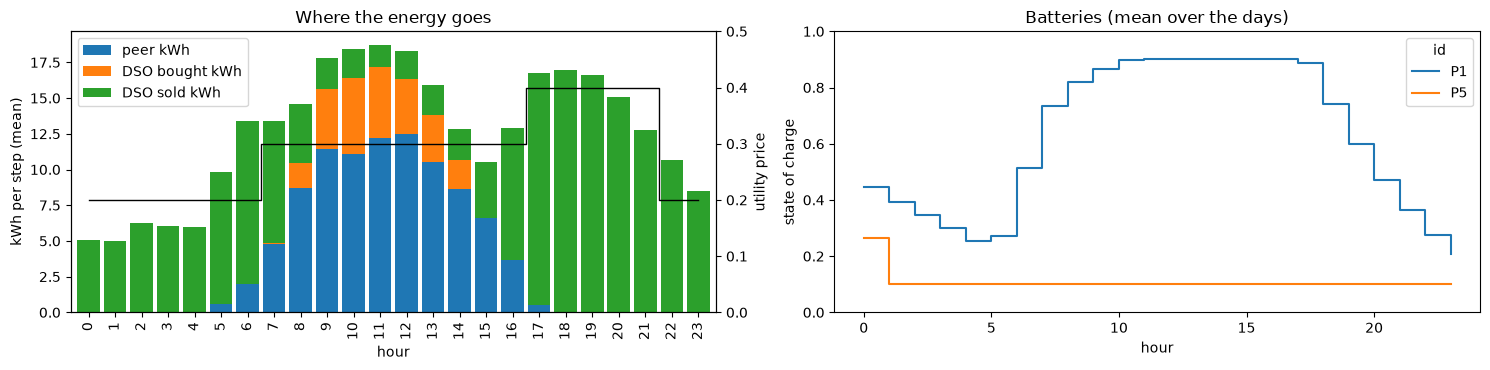

In [6]:
# The mean over the days, by hour
by_hour = steps.groupby("step")[["peer kWh", "DSO bought kWh", "DSO sold kWh", "utility", "both sides"]].mean()

# Each battery's state of charge after every step
capacity = {}
for p in scenario.participants:
    if p.battery:
        capacity[p.id] = p.battery.capacity_kwh

rows = []
for day, lem, records in played:
    for r in records:
        for pid, out in r.participants.items():
            if out.soc_kwh is not None:
                rows.append({"step": r.step, "id": pid, "soc": out.soc_kwh / capacity[pid]})
soc = pd.DataFrame(rows).pivot_table(index="step", columns="id", values="soc")   # mean over days

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 3.8))

by_hour[["peer kWh", "DSO bought kWh", "DSO sold kWh"]].plot.bar(ax=left, stacked=True, width=0.85)
left.set_xlabel("hour")
left.set_ylabel("kWh per step (mean)")
left.set_title("Where the energy goes")
price = left.twinx()
price.step(range(24), by_hour.utility, where="mid", color="black", linewidth=1)
price.set_ylabel("utility price")
price.set_ylim(0, 0.5)

soc.plot(ax=right, drawstyle="steps-post")
right.set_xlabel("hour")
right.set_ylabel("state of charge")
right.set_ylim(0, 1)
right.set_title("Batteries (mean over the days)")

plt.tight_layout()
plt.show()

### Fees by part, and the participants

Which parts of eq. 8 the fees come from over the 14 days (a negative part is the
zone bonus), and what each participant traded, paid and earned. A participant's
`fees` can be negative: the zone bonus outweighs its other fee parts.

In [7]:
# Each fee part, summed over every step
parts = {}
for part in FEE_PARTS:
    parts[part] = steps[f"fee {part}"].sum()
display(pd.Series(parts).to_frame("total over the days").T)

# One row per participant per step
rows = []
for day, lem, records in played:
    last_step = len(records) - 1
    for r in records:
        for pid, out in r.participants.items():
            rows.append({"id": pid, "day": day, "sold kWh": out.sold_kwh, "bought kWh": out.bought_kwh,
                         "fees": out.fees, "profit": out.profit,
                         "reputation": r.reputation[pid].reputation, "last": r.step == last_step})
people = pd.DataFrame(rows)

summary = people.groupby("id")[["sold kWh", "bought kWh", "fees", "profit"]].sum()
at_midnight = people[people["last"]]
summary["reputation at midnight (mean)"] = at_midnight.groupby("id").reputation.mean()
summary

,congestion,transmission,imbalance,voltage,thermal,zone
total over the days,0.0,4.813,0.0,24.064,0.102,-17.661


,sold kWh,bought kWh,fees,profit,reputation at midnight (mean)
id,,,,,
P1,1072.869,2.086,-6.930,187.383,0.550
P2,589.119,41.964,1.378,79.135,0.434
P3,0.000,1491.518,8.770,-410.081,0.405
P4,0.000,1491.518,11.442,-411.941,0.407
P5,0.000,847.076,-3.341,-211.144,0.426


### Reputation through one day

Every reputation starts at 0.5 each day. With a decay of 0.8 per hour, a step's
score has half its weight after about 3 hours: reputation follows the last few
hours, not the whole day (open points M-43, M-45).

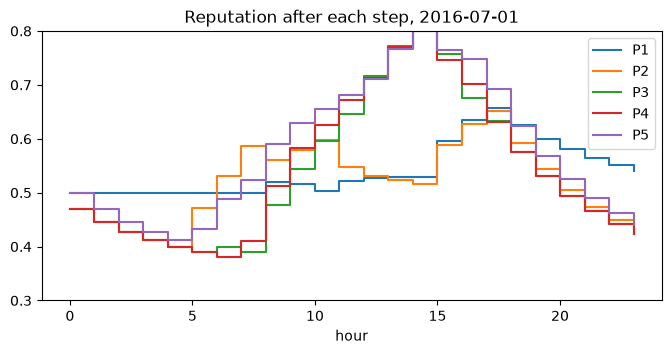

In [8]:
day, lem, records = played[0]

rows = []
for r in records:
    row = {}
    for pid, u in r.reputation.items():
        row[pid] = u.reputation
    rows.append(row)
rep = pd.DataFrame(rows)    # one row per step, one column per participant

ax = rep.plot(drawstyle="steps-post", figsize=(8, 3.5), title=f"Reputation after each step, {day}")
ax.set_xlabel("hour")
ax.set_ylim(0.3, 0.8)
plt.show()

## Experiments: change one setting

`compare` plays the first days of each variant and puts the totals and the
number of failed rules side by side. The rules are the same; only the
"bidding rule" one is expected to change when the bids do.

In [9]:
def compare(days: list[str], **variants: Scenario) -> pd.DataFrame:
    # Play each variant on the days; one column of totals per variant.
    columns = {}
    for name, s in variants.items():
        runs = run_days(s, days)
        records = []
        for day, lem, day_records in runs:
            records.extend(day_records)

        failed = (check_days(s, runs).result == "FAIL").sum()
        columns[name] = {
            "peer kWh": sum(r.p2p_kwh for r in records),
            "DSO kWh": sum(r.dso_kwh for r in records),
            "fees": sum(r.fees for r in records),
            "DSO profit": sum(r.dso.profit for r in records),
            "rules failed": failed,
        }
    return pd.DataFrame(columns)


def variant(**changes) -> Scenario:
    # A copy of the reference scenario with some settings changed,
    # written part__field=value, e.g. market__bid_margin=0.6
    s = deepcopy(scenario)
    for path, value in changes.items():
        part, field = path.split("__")
        setattr(getattr(s, part), field, value)
    return s


compare(DAYS[:3],
        reference=scenario,
        bids_never_cross=variant(market__bid_margin=0.6),
        no_partner_preference=variant(market__partner_preference=False),
        flat_tariffs=variant(dso__prices=None),
        fees_not_charged=variant(dso__fees_charged=False),
        graph_method=variant(grid__method="graph"))

,reference,bids_never_cross,no_partner_preference,flat_tariffs,fees_not_charged,graph_method
peer kWh,274.318,0.000,274.318,274.318,274.318,274.318
DSO kWh,612.290,1160.926,612.290,612.290,612.290,612.290
fees,2.622,13.005,3.152,2.593,2.622,40.271
DSO profit,140.541,210.733,141.072,139.691,137.920,178.190
rules failed,0.000,0.000,0.000,0.000,0.000,0.000
